# Figure: one RWG basis function on a real mesh

Generates `documentation/source/figures/generated/rwg_basis_function.svg`, used on the page *Theory → RWG basis functions*.

The mesh and the RWG data come from the solver itself (`solver.rwg.rwg1`, `solver.rwg.rwg2`), with the same preprocessing sequence as `radiation_algorithm()`. Before drawing anything, the notebook checks numerically the properties the documentation page states (cell 4). A provenance file (`rwg_basis_function.json`) records the solver commit and the check results.

Run it from this folder with the `antenna_solver` environment. Nothing is written to `data/`.

In [1]:
%matplotlib inline
import datetime
import json
from pathlib import Path

import gmsh
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon

from solver.rwg.rwg1 import Points, Triangles, filter_complexes_jonctions
from solver.rwg.rwg2 import Vecteurs_Rho

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE = OUT_DIR / "rwg_basis_function.svg"

In [2]:
# A 100 mm x 60 mm plate meshed by gmsh, kept in memory (no .msh/.mat file written).
LX, LY, H = 0.100, 0.060, 0.020   # plate size and target element size (m)

gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
gmsh.option.setNumber("General.NumThreads", 1)   # single thread: the mesh is reproducible
gmsh.model.add("rwg_plate")
gmsh.model.occ.addRectangle(0, 0, 0, LX, LY)
gmsh.model.occ.synchronize()
gmsh.option.setNumber("Mesh.MeshSizeMin", H)
gmsh.option.setNumber("Mesh.MeshSizeMax", H)
gmsh.model.mesh.generate(2)

node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
p = np.asarray(node_coords).reshape(-1, 3).T                  # (3, N) coordinates
index_of = {int(tag): i for i, tag in enumerate(node_tags)}
blocks = []
for dim, surface in gmsh.model.getEntities(2):
    types, _, nodes = gmsh.model.mesh.getElements(dim, surface)
    for etype, enodes in zip(types, nodes):
        if etype == 2:                                         # 3-node triangle
            idx = np.array([index_of[int(k)] for k in enodes]).reshape(-1, 3).T
            blocks.append(np.vstack([idx, np.full((1, idx.shape[1]), surface)]))
gmsh.finalize()

t = np.hstack(blocks).astype(int)   # (4, M): 0-based vertex indices + surface label
print(f"{p.shape[1]} nodes, {t.shape[1]} triangles")

30 nodes, 42 triangles


In [3]:
# RWG preprocessing, same sequence as solver/src/radiation_algorithm/radiation_algorithm.py
points = Points(p)
triangles = Triangles(t)
triangles.calculate_triangles_area_and_center(points)
edges = triangles.get_edges()
filter_complexes_jonctions(points, triangles, edges)
edges.compute_edges_length(points)

rho = Vecteurs_Rho()
rho.calculate_vecteurs_rho(points, triangles, edges)
print(f"{edges.total_number_of_edges} RWG basis functions (one per interior edge)")

55 RWG basis functions (one per interior edge)


In [4]:
# Pick the basis function whose edge is closest to the plate centre.
P = points.points
mid = 0.5 * (P[:, edges.first_points] + P[:, edges.second_points])
n = int(np.argmin(np.linalg.norm(mid[:2] - np.array([[LX / 2], [LY / 2]]), axis=0)))

a, b = edges.first_points[n], edges.second_points[n]
tp, tm = triangles.triangles_plus[n], triangles.triangles_minus[n]
l_n = edges.edges_length[n]
A_p, A_m = triangles.triangles_area[tp], triangles.triangles_area[tm]

def free_vertex(tri):
    """Vertex of `tri` that is not on edge n."""
    return P[:, [v for v in triangles.triangles[:3, tri] if v not in (a, b)][0]]

v_p, v_m = free_vertex(tp), free_vertex(tm)
c_p, c_m = triangles.triangles_center[:, tp], triangles.triangles_center[:, tm]

# The definition (Rao, Wilton & Glisson 1982), written independently of the solver.
def f_plus(r):    # r: (3, K) points of T+
    return l_n / (2 * A_p) * (r - v_p[:, None])

def f_minus(r):   # r: (3, K) points of T-
    return l_n / (2 * A_m) * (v_m[:, None] - r)

checks = {}

# 1. The solver's rho vectors (rwg2.Vecteurs_Rho) are the definition taken at the centroids.
checks["rho_plus_equals_centroid_minus_free_vertex"] = bool(np.allclose(rho.vecteur_rho_plus[:, n], c_p - v_p))
checks["rho_minus_equals_free_vertex_minus_centroid"] = bool(np.allclose(rho.vecteur_rho_minus[:, n], v_m - c_m))

# 2. Across edge n the normal component is 1 on both sides: the current is continuous.
s = np.linspace(0.0, 1.0, 7)
tangent = (P[:, b] - P[:, a]) / l_n
normal = np.cross(np.cross(tangent, v_m - v_p), tangent)
normal /= np.linalg.norm(normal)                      # in the plane, pointing from T+ to T-
on_edge = P[:, [a]] + (P[:, [b]] - P[:, [a]]) * s
checks["normal_component_on_edge_n_from_Tplus"] = [round(float(x), 12) for x in normal @ f_plus(on_edge)]
checks["normal_component_on_edge_n_from_Tminus"] = [round(float(x), 12) for x in normal @ f_minus(on_edge)]

# 3. On the four other edges of the pair the normal component vanishes: no charge leaves the pair.
def max_normal(start, end, inside, f):
    tv = (end - start) / np.linalg.norm(end - start)
    nv = np.cross(np.cross(tv, inside - start), tv)
    nv /= np.linalg.norm(nv)
    return float(np.max(np.abs(nv @ f(start[:, None] + (end - start)[:, None] * s))))

checks["max_normal_component_on_outer_edges"] = max(
    max_normal(v_p, P[:, a], c_p, f_plus), max_normal(v_p, P[:, b], c_p, f_plus),
    max_normal(v_m, P[:, a], c_m, f_minus), max_normal(v_m, P[:, b], c_m, f_minus))

# 4. Surface divergence, by central finite differences, against +l/A+ and -l/A-.
def divergence(f, r0, h=1e-7):
    total = 0.0
    for k in range(2):                      # the plate lies in z = 0
        e = np.zeros((3, 1)); e[k] = h
        total += (f(r0 + e)[k, 0] - f(r0 - e)[k, 0]) / (2 * h)
    return float(total)

checks["divergence_Tplus_numeric_vs_l_over_A"] = [divergence(f_plus, c_p[:, None]), float(l_n / A_p)]
checks["divergence_Tminus_numeric_vs_minus_l_over_A"] = [divergence(f_minus, c_m[:, None]), float(-l_n / A_m)]

assert checks["rho_plus_equals_centroid_minus_free_vertex"]
assert checks["rho_minus_equals_free_vertex_minus_centroid"]
assert np.allclose(checks["normal_component_on_edge_n_from_Tplus"], 1.0)
assert np.allclose(checks["normal_component_on_edge_n_from_Tminus"], 1.0)
assert checks["max_normal_component_on_outer_edges"] < 1e-12
assert np.isclose(*checks["divergence_Tplus_numeric_vs_l_over_A"], rtol=1e-6)
assert np.isclose(*checks["divergence_Tminus_numeric_vs_minus_l_over_A"], rtol=1e-6)
print(f"edge n = {n}, l_n = {l_n*1e3:.2f} mm, A+ = {A_p*1e6:.1f} mm^2, A- = {A_m*1e6:.1f} mm^2")
print(json.dumps(checks, indent=1))

edge n = 47, l_n = 20.03 mm, A+ = 133.4 mm^2, A- = 133.4 mm^2
{
 "rho_plus_equals_centroid_minus_free_vertex": true,
 "rho_minus_equals_free_vertex_minus_centroid": true,
 "normal_component_on_edge_n_from_Tplus": [
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0
 ],
 "normal_component_on_edge_n_from_Tminus": [
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0
 ],
 "max_normal_component_on_outer_edges": 3.3306690738754696e-16,
 "divergence_Tplus_numeric_vs_l_over_A": [
  150.2397636341267,
  150.23976363288958
 ],
 "divergence_Tminus_numeric_vs_minus_l_over_A": [
  -150.23976363745788,
  -150.2397636328897
 ]
}


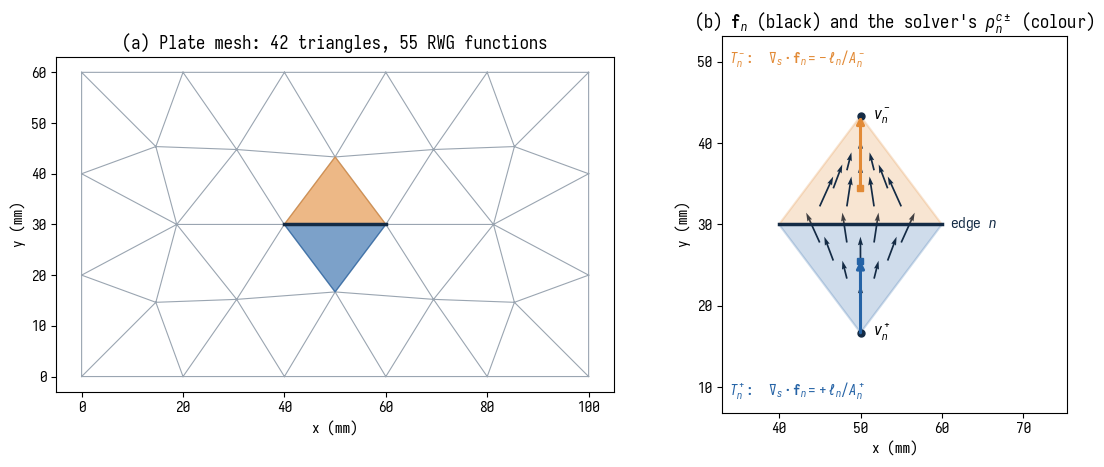

In [5]:
# Colours of the site logo: T+ blue, T- amber, dark ink for lines and arrows.
BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
mm = 1e3

# The site's own font files (Iosevka, documentation/source/_static/fonts/iosevka), converted
# from woff2 to ttf in a temporary folder, so that figures and pages use exactly the same font.
import tempfile
from fontTools.ttLib import TTFont
from matplotlib import font_manager
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None                                     # woff2 -> plain TrueType
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

def corners(tri):
    return P[:2, triangles.triangles[:3, tri]].T * mm

def interior_points(tri, n_sub=6):
    """Barycentric grid strictly inside the triangle."""
    V = P[:, triangles.triangles[:3, tri]]
    pts = [V @ np.array([i, j, n_sub - i - j]) / n_sub
           for i in range(1, n_sub) for j in range(1, n_sub - i)]
    return np.array(pts).T

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

# (a) the whole mesh, with the pair carrying basis function n
ax0.triplot(P[0] * mm, P[1] * mm, triangles.triangles[:3].T, color=GREY, lw=0.8)
for tri, col in ((tp, BLUE), (tm, AMBER)):
    ax0.add_patch(Polygon(corners(tri), closed=True, fc=col, ec=col, alpha=0.6))
ax0.plot(P[0, [a, b]] * mm, P[1, [a, b]] * mm, color=INK, lw=2.5)
ax0.set_title("(a) Plate mesh: %d triangles, %d RWG functions" % (triangles.total_of_triangles, edges.total_number_of_edges))

# (b) the basis function on its two triangles
arrow_scale = 1.0 / (0.22 * H * mm)    # an arrow of length 0.22*H for |f| = 1
for tri, col, f in ((tp, BLUE, f_plus), (tm, AMBER, f_minus)):
    ax1.add_patch(Polygon(corners(tri), closed=True, fc=col, ec=col, alpha=0.22, lw=1.5))
    r = interior_points(tri)
    fr = f(r)
    ax1.quiver(r[0] * mm, r[1] * mm, fr[0], fr[1], color=INK, angles="xy",
               scale_units="xy", scale=arrow_scale, width=0.005)

# Edge n, labelled beyond its right-hand end so that no arrow is hidden
ax1.plot(P[0, [a, b]] * mm, P[1, [a, b]] * mm, color=INK, lw=2.5)
end = max((P[:2, a], P[:2, b]), key=lambda q: q[0]) * mm
ax1.annotate(r"edge $n$", end, xytext=(6, 0), textcoords="offset points", ha="left", va="center",
             fontsize=11, color=INK)

# The solver's rho vectors at the centroids (rwg2.Vecteurs_Rho)
for start, vec, col in ((v_p, rho.vecteur_rho_plus[:, n], BLUE), (c_m, rho.vecteur_rho_minus[:, n], AMBER)):
    ax1.annotate("", xy=(start[:2] + vec[:2]) * mm, xytext=start[:2] * mm,
                 arrowprops=dict(arrowstyle="-|>", color=col, lw=2.2, shrinkA=0, shrinkB=0))

for v, label in ((v_p, r"$v_n^+$"), (v_m, r"$v_n^-$")):
    ax1.plot(*(v[:2] * mm), "o", color=INK, ms=5)
    ax1.annotate(label, v[:2] * mm, xytext=(9, 0), textcoords="offset points",
                 ha="left", va="center", fontsize=12)

for c, col in ((c_p, BLUE), (c_m, AMBER)):   # centroids
    ax1.plot(*(c[:2] * mm), "s", color=col, ms=5)

# Triangle names and divergences, written on the side of their own triangle
plus_is_lower = c_p[1] < c_m[1]
for c, text, col in ((c_p, r"$T_n^+$:  $\nabla_s\cdot\mathbf{f}_n=+\ell_n/A_n^+$", BLUE),
                     (c_m, r"$T_n^-$:  $\nabla_s\cdot\mathbf{f}_n=-\ell_n/A_n^-$", AMBER)):
    lower = (c is c_p) == plus_is_lower
    ax1.text(0.02, 0.03 if lower else 0.97, text, transform=ax1.transAxes,
             va="bottom" if lower else "top", ha="left", color=col, fontsize=11)
ax1.set_title(r"(b) $\mathbf{f}_n$ (black) and the solver's $\rho_n^{c\pm}$ (colour)")

pair = np.hstack([corners(tp).T, corners(tm).T])
pad = 0.35 * H * mm
ax1.set_xlim(pair[0].min() - pad, pair[0].max() + 2.2 * pad)
ax1.set_ylim(pair[1].min() - 1.4 * pad, pair[1].max() + 1.4 * pad)

for ax in (ax0, ax1):
    ax.set_aspect("equal")
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")

fig.tight_layout()
fig.savefig(FIGURE, bbox_inches="tight", facecolor="white")
plt.show()

In [6]:
# Provenance: which solver code produced the figure, and what was checked.
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]                                   # detached HEAD
    ref = head[5:]
    ref_file = git_dir / ref
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():   # packed refs
        if line.endswith(" " + ref):
            return line.split()[0][:7]
    return "unknown"

provenance = {
    "figure": FIGURE.name,
    "notebook": "documentation/figure_notebooks/theory_rwg_basis_function.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "solver_calls": ["solver.rwg.rwg1.Triangles.get_edges", "solver.rwg.rwg1.filter_complexes_jonctions",
                     "solver.rwg.rwg2.Vecteurs_Rho.calculate_vecteurs_rho"],
    "mesh": {"plate_m": [LX, LY], "element_size_m": H, "triangles": int(triangles.total_of_triangles),
             "rwg_functions": int(edges.total_number_of_edges)},
    "edge_index": n,
    "checks": checks,
}
(OUT_DIR / "rwg_basis_function.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps(provenance, indent=2))

{
  "figure": "rwg_basis_function.svg",
  "notebook": "documentation/figure_notebooks/theory_rwg_basis_function.ipynb",
  "solver_commit": "7c348a7",
  "generated": "2026-11-11",
  "solver_calls": [
    "solver.rwg.rwg1.Triangles.get_edges",
    "solver.rwg.rwg1.filter_complexes_jonctions",
    "solver.rwg.rwg2.Vecteurs_Rho.calculate_vecteurs_rho"
  ],
  "mesh": {
    "plate_m": [
      0.1,
      0.06
    ],
    "element_size_m": 0.02,
    "triangles": 42,
    "rwg_functions": 55
  },
  "edge_index": 47,
  "checks": {
    "rho_plus_equals_centroid_minus_free_vertex": true,
    "rho_minus_equals_free_vertex_minus_centroid": true,
    "normal_component_on_edge_n_from_Tplus": [
      1.0,
      1.0,
      1.0,
      1.0,
      1.0,
      1.0,
      1.0
    ],
    "normal_component_on_edge_n_from_Tminus": [
      1.0,
      1.0,
      1.0,
      1.0,
      1.0,
      1.0,
      1.0
    ],
    "max_normal_component_on_outer_edges": 3.3306690738754696e-16,
    "divergence_Tplus_numeric_vs_l